Variância explicada:
PC1: 54.21%
PC2: 20.40%
PC3: 19.39%
PC4: 3.94%
PC5: 2.07%

Variância acumulada nos 2 primeiros componentes: 74.61%


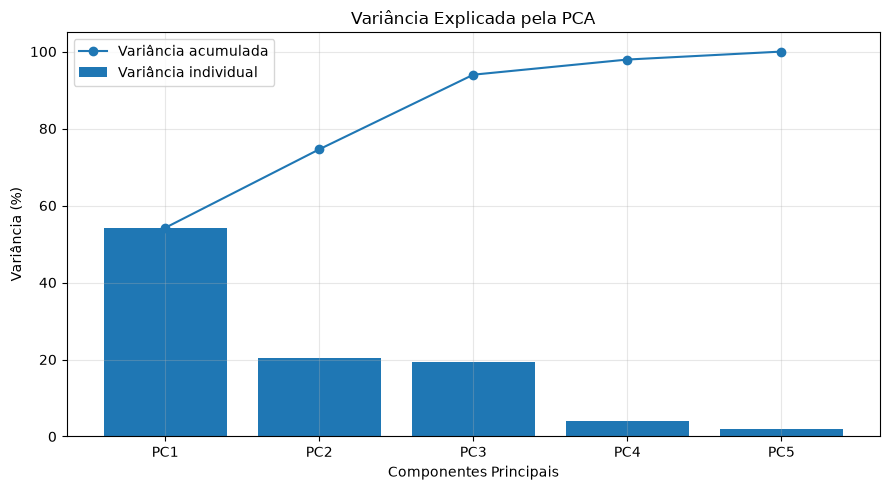

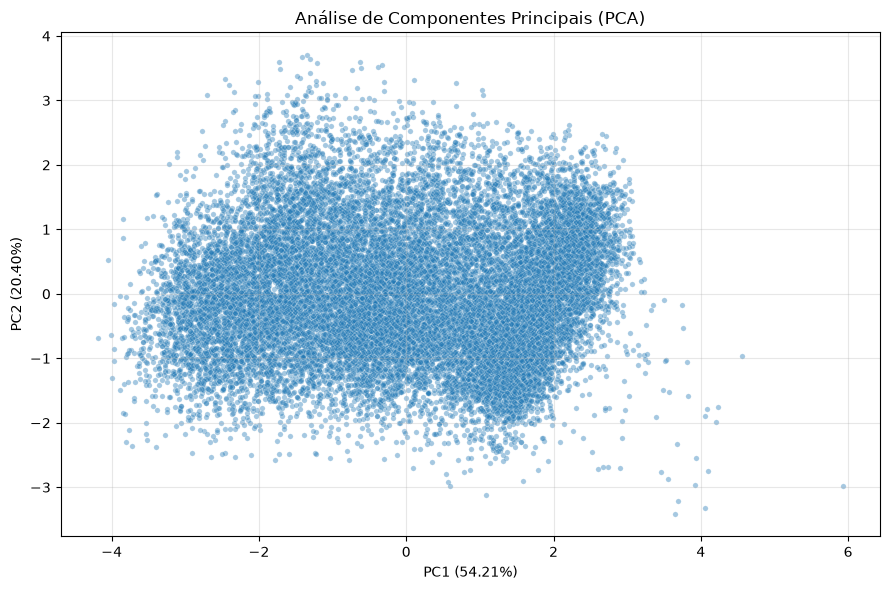


Contribuição das variáveis:
                                                      PC1    PC2
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       -0.574 -0.103
UMIDADE RELATIVA DO AR, HORARIA (%)                 0.581 -0.085
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARI...  0.178  0.937
VENTO, VELOCIDADE HORARIA (m/s)                    -0.529  0.312
PRECIPITAÇÃO TOTAL, HORÁRIO (mm)                    0.145 -0.080


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv(r'C:\Users\W2 ASSISTENCIA\Downloads\PSI3\dados\df_recife_datetime.csv')

variaveis = [
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)',
    'VENTO, VELOCIDADE HORARIA (m/s)',
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'
]

dados = df[variaveis].copy()

dados = dados.apply(pd.to_numeric, errors='coerce')
dados = dados.dropna()

scaler = StandardScaler()
dados_padronizados = scaler.fit_transform(dados)

pca = PCA()
componentes = pca.fit_transform(dados_padronizados)

variancia = pca.explained_variance_ratio_ * 100
variancia_acumulada = variancia.cumsum()

print('Variância explicada:')
for i, valor in enumerate(variancia):
    print(f'PC{i+1}: {valor:.2f}%')

print(f'\nVariância acumulada nos 2 primeiros componentes: {variancia_acumulada[1]:.2f}%')

plt.figure(figsize=(9, 5))

plt.bar(
    [f'PC{i+1}' for i in range(len(variancia))],
    variancia,
    label='Variância individual'
)

plt.plot(
    [f'PC{i+1}' for i in range(len(variancia))],
    variancia_acumulada,
    marker='o',
    label='Variância acumulada'
)

plt.title('Variância Explicada pela PCA')
plt.xlabel('Componentes Principais')
plt.ylabel('Variância (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

df_pca = pd.DataFrame(
    componentes[:, :2],
    columns=['PC1', 'PC2']
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    alpha=0.4,
    s=15
)

plt.title('Análise de Componentes Principais (PCA)')
plt.xlabel(f'PC1 ({variancia[0]:.2f}%)')
plt.ylabel(f'PC2 ({variancia[1]:.2f}%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

contribuicoes = pd.DataFrame(
    pca.components_[:2].T,
    index=variaveis,
    columns=['PC1', 'PC2']
)

print('\nContribuição das variáveis:')
print(contribuicoes.round(3))


## Resultados da Análise de Componentes Principais (PCA)

A aplicação da PCA sobre as variáveis meteorológicas (Temperatura, Umidade, Pressão, Vento e Precipitação) permitiu resumir a multidimensionalidade dos dados em eixos sintéticos principais, cujos resultados são detalhados abaixo:

Variância Explicada e Acumulada (Scree Plot):
  * O primeiro componente principal isoladamente é responsável por reter 54,21% da variância total dos dados.
  * O segundo componente PC2 explica cerca de 20,40%.
  * Juntos, PC1 e PC2 acumulam aproximadamente 74,61% de toda a informação contida nas cinco variáveis originais.
  * Nota-se também que os três primeiros componentes (PC1, PC2 e PC3) ultrapassam a marca de 90% de variância acumulada.

Distribuição Fatorial (Scatter Plot de PC1 vs PC2):
  * O gráfico de dispersão dos pontos no espaço formado por PC1 e PC2 demonstra uma grande densidade de registros concentrada próxima à região central (valores entre -2 e 2 nos eixos).
  * A forma da nuvem de pontos revela um comportamento contínuo das condições meteorológicas horárias, com alguns *outliers* (pontos mais isolados à direita e na parte inferior), correspondendo a momentos de registros atípicos ou eventos extremos de vento/precipitação na série histórica.